
# Global Life Expectancy Analysis

## 01 — Data Exploration

### Project Objective

Explore how life expectancy has evolved across countries and World Bank income groups between 1960 and 2023.

### Data Sources

World Bank Open Data.

### Indicators

1. Total life expectancy at birth
2. Male life expectancy at birth
3. Female life expectancy at birth
4. Crude death rate
5. Total fertility rate

### Objectives of This Notebook

1. Understand the structure and coverage of the dataset.
2. Examine country and regional representation.
3. Explore indicator distributions.
4. Investigate life expectancy trends.
5. Identify initial patterns, anomalies and data-quality issues.

**Analysis period:** 1960–2023


In [1]:
from pathlib import Path
import sys

# Find the project root (the folder containing src/)
current_path = Path.cwd()

if not (current_path / "src").exists():
    current_path = current_path.parent

PROJECT_ROOT = current_path

# Add project root to Python's import search path
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)
print("src folder found:", (PROJECT_ROOT / "src").exists())

Project root: /Users/jp/Documents/Personal-Projects/nxp_life_expectancy_analysis
src folder found: True


In [2]:

# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import build_dataset
from src.config import START_YEAR, END_YEAR

# Display configuration
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

# Visualization style
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")


Libraries imported successfully!


In [3]:
# Load the processed dataset

df = build_dataset()

print("Dataset loaded successfully!")
print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")
# Preview the dataset

display(df.head(10))

Loading existing processed dataset.
Dataset loaded successfully!
Number of rows: 17,024
Number of columns: 12


,country,country_code,year,life_expectancy_total,life_expectancy_male,life_expectancy_female,death_rate,fertility_rate,region,income_group,metadata_country,observation_type
0,Aruba,ABW,1960,64.05,60.75,67.46,7.53,4.57,Latin America & Caribbean,High income,Aruba,Country
1,Aruba,ABW,1961,64.22,61.11,67.39,7.35,4.42,Latin America & Caribbean,High income,Aruba,Country
2,Aruba,ABW,1962,64.60,61.37,67.92,7.07,4.26,Latin America & Caribbean,High income,Aruba,Country
3,Aruba,ABW,1963,64.94,61.60,68.39,6.86,4.11,Latin America & Caribbean,High income,Aruba,Country
4,Aruba,ABW,1964,65.30,61.82,68.90,6.69,3.94,Latin America & Caribbean,High income,Aruba,Country
5,Aruba,ABW,1965,65.61,62.05,69.32,6.57,3.80,Latin America & Caribbean,High income,Aruba,Country
6,Aruba,ABW,1966,66.13,62.58,69.79,6.38,3.62,Latin America & Caribbean,High income,Aruba,Country
7,Aruba,ABW,1967,66.39,62.76,70.14,6.35,3.45,Latin America & Caribbean,High income,Aruba,Country
8,Aruba,ABW,1968,66.74,63.09,70.54,6.26,3.28,Latin America & Caribbean,High income,Aruba,Country
9,Aruba,ABW,1969,67.10,63.42,70.92,6.19,3.11,Latin America & Caribbean,High income,Aruba,Country


In [4]:
# Count records by observation type

observation_counts = (
    df["observation_type"]
    .value_counts()
    .rename_axis("observation_type")
    .reset_index(name="record_count")
)

display(observation_counts)

,observation_type,record_count
0,Country,13888
1,Regional aggregate,3072
2,Unclassified,64


In [5]:
# Inspect column names, data types and non-null counts

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17024 entries, 0 to 17023
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   country                 17024 non-null  object 
 1   country_code            17024 non-null  object 
 2   year                    17024 non-null  int64  
 3   life_expectancy_total   16926 non-null  float64
 4   life_expectancy_male    16926 non-null  float64
 5   life_expectancy_female  16926 non-null  float64
 6   death_rate              16930 non-null  float64
 7   fertility_rate          16928 non-null  float64
 8   region                  13888 non-null  object 
 9   income_group            13888 non-null  object 
 10  metadata_country        16960 non-null  object 
 11  observation_type        17024 non-null  object 
dtypes: float64(5), int64(1), object(6)
memory usage: 1.6+ MB


In [6]:
# Calculate missing values for each indicator

missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": df.isna().mean() * 100
})

display(missing_summary.sort_values(
    by="missing_percentage",
    ascending=False
))

,missing_count,missing_percentage
region,3136,18.42
income_group,3136,18.42
life_expectancy_total,98,0.58
life_expectancy_male,98,0.58
life_expectancy_female,98,0.58
fertility_rate,96,0.56
death_rate,94,0.55
metadata_country,64,0.38
country,0,0.00
country_code,0,0.00


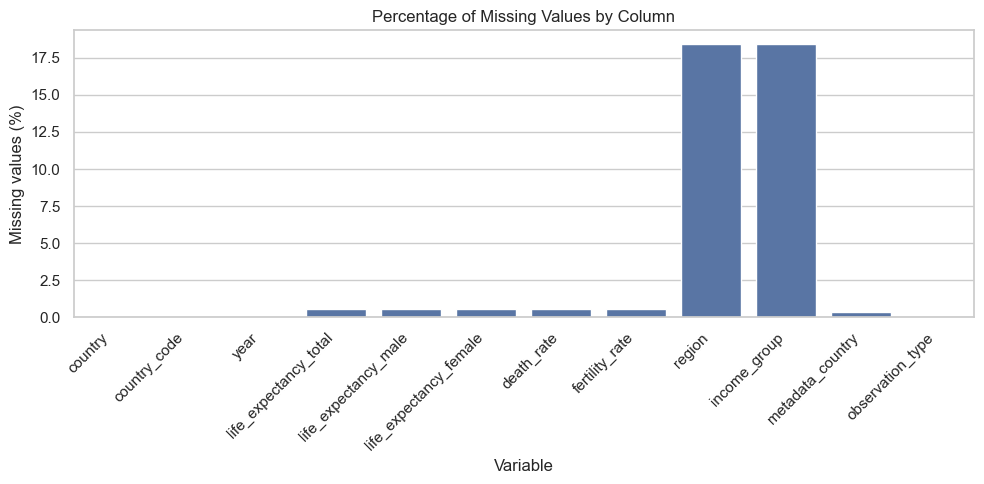

In [7]:
# Visualize missing values by column

plt.figure(figsize=(10, 5))

sns.barplot(
    x=missing_summary.index,
    y=missing_summary["missing_percentage"]
)

plt.title("Percentage of Missing Values by Column")
plt.xlabel("Variable")
plt.ylabel("Missing values (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [8]:
# Check how many observations are available for each year

year_coverage = (
    df.groupby("year")
    .agg(
        total_records=("country_code", "count"),
        unique_observations=("country_code", "nunique")
    )
    .reset_index()
)

display(year_coverage.head())
display(year_coverage.tail())

print("Earliest year:", df["year"].min())
print("Latest year:", df["year"].max())
print("Number of years:", df["year"].nunique())

,year,total_records,unique_observations
0,1960,266,266
1,1961,266,266
2,1962,266,266
3,1963,266,266
4,1964,266,266


,year,total_records,unique_observations
59,2019,266,266
60,2020,266,266
61,2021,266,266
62,2022,266,266
63,2023,266,266


Earliest year: 1960
Latest year: 2023
Number of years: 64


In [9]:
indicator_columns = [
    "life_expectancy_total",
    "life_expectancy_male",
    "life_expectancy_female",
    "death_rate",
    "fertility_rate"
]

missing_by_type = (
    df.groupby("observation_type")[indicator_columns]
    .agg(lambda x: x.isna().sum())
)

display(missing_by_type)

,life_expectancy_total,life_expectancy_male,life_expectancy_female,death_rate,fertility_rate
observation_type,,,,,
Country,34,34,34,30,32
Regional aggregate,0,0,0,0,0
Unclassified,64,64,64,64,64


In [10]:
year_coverage = (
    df.groupby("year")
    .agg(
        total_records=("country_code", "count"),
        unique_observations=("country_code", "nunique")
    )
    .reset_index()
)

display(year_coverage.head(10))
display(year_coverage.tail(10))

print("Earliest year:", df["year"].min())
print("Latest year:", df["year"].max())
print("Number of years:", df["year"].nunique())

,year,total_records,unique_observations
0,1960,266,266
1,1961,266,266
2,1962,266,266
3,1963,266,266
4,1964,266,266
5,1965,266,266
6,1966,266,266
7,1967,266,266
8,1968,266,266
9,1969,266,266


,year,total_records,unique_observations
54,2014,266,266
55,2015,266,266
56,2016,266,266
57,2017,266,266
58,2018,266,266
59,2019,266,266
60,2020,266,266
61,2021,266,266
62,2022,266,266
63,2023,266,266


Earliest year: 1960
Latest year: 2023
Number of years: 64


In [11]:
# Keep only individual country observations

country_df = df[
    df["observation_type"] == "Country"
].copy()

print("Country-level dataset")
print("---------------------")
print("Rows:", len(country_df))
print("Unique countries:", country_df["country_code"].nunique())
print("Years:", country_df["year"].nunique())

display(country_df.head())

Country-level dataset
---------------------
Rows: 13888
Unique countries: 217
Years: 64


,country,country_code,year,life_expectancy_total,life_expectancy_male,life_expectancy_female,death_rate,fertility_rate,region,income_group,metadata_country,observation_type
0,Aruba,ABW,1960,64.05,60.75,67.46,7.53,4.57,Latin America & Caribbean,High income,Aruba,Country
1,Aruba,ABW,1961,64.22,61.11,67.39,7.35,4.42,Latin America & Caribbean,High income,Aruba,Country
2,Aruba,ABW,1962,64.60,61.37,67.92,7.07,4.26,Latin America & Caribbean,High income,Aruba,Country
3,Aruba,ABW,1963,64.94,61.60,68.39,6.86,4.11,Latin America & Caribbean,High income,Aruba,Country
4,Aruba,ABW,1964,65.30,61.82,68.90,6.69,3.94,Latin America & Caribbean,High income,Aruba,Country


In [12]:
global_trend = (
    country_df.groupby("year")["life_expectancy_total"]
    .agg(
        mean_life_expectancy="mean",
        median_life_expectancy="median",
        country_count="count"
    )
    .reset_index()
)

display(global_trend.head())
display(global_trend.tail())

,year,mean_life_expectancy,median_life_expectancy,country_count
0,1960,54.90,56.54,215
1,1961,55.44,57.15,216
2,1962,55.89,57.78,216
3,1963,56.19,58.10,215
4,1964,56.70,58.17,215


,year,mean_life_expectancy,median_life_expectancy,country_count
59,2019,73.03,74.17,217
60,2020,72.50,72.99,217
61,2021,71.80,72.28,217
62,2022,73.11,74.21,217
63,2023,73.79,74.55,217


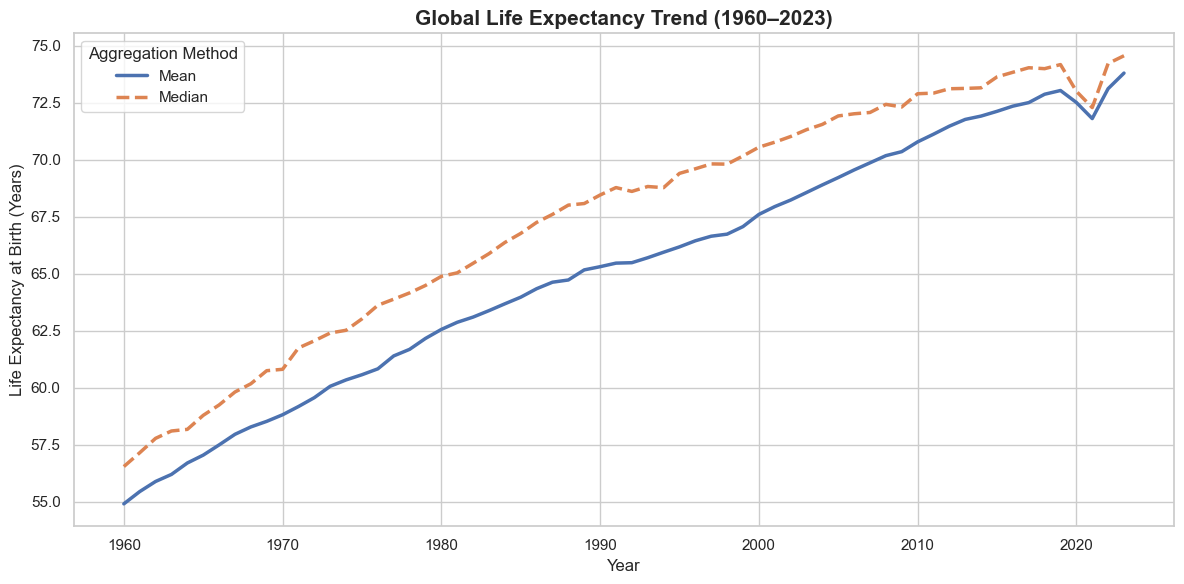

In [13]:
plt.figure(figsize=(12, 6))

# Mean trend
sns.lineplot(
    data=global_trend,
    x="year",
    y="mean_life_expectancy",
    label="Mean",
    linewidth=2.5
)

# Median trend
sns.lineplot(
    data=global_trend,
    x="year",
    y="median_life_expectancy",
    label="Median",
    linewidth=2.5,
    linestyle="--"
)

plt.title(
    "Global Life Expectancy Trend (1960–2023)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Year")
plt.ylabel("Life Expectancy at Birth (Years)")

plt.legend(title="Aggregation Method")
plt.tight_layout()
plt.show()

In [14]:
print("1960")
display(global_trend[global_trend["year"] == 1960])

print("2023")
display(global_trend[global_trend["year"] == 2023])

1960


,year,mean_life_expectancy,median_life_expectancy,country_count
0,1960,54.90,56.54,215


2023


,year,mean_life_expectancy,median_life_expectancy,country_count
63,2023,73.79,74.55,217


In [15]:
start_value = global_trend.loc[
    global_trend["year"] == 1960,
    "mean_life_expectancy"
].iloc[0]

end_value = global_trend.loc[
    global_trend["year"] == 2023,
    "mean_life_expectancy"
].iloc[0]

print(f"Average life expectancy in 1960: {start_value:.2f}")
print(f"Average life expectancy in 2023: {end_value:.2f}")
print(f"Change: {end_value - start_value:.2f} years")

Average life expectancy in 1960: 54.90
Average life expectancy in 2023: 73.79
Change: 18.89 years


By Income Group

In [16]:
# Calculate mean and median life expectancy by income group and year

income_trend = (
    country_df
    .dropna(subset=["income_group", "life_expectancy_total"])
    .groupby(["year", "income_group"])["life_expectancy_total"]
    .agg(
        mean_life_expectancy="mean",
        median_life_expectancy="median",
        country_count="count"
    )
    .reset_index()
)

display(income_trend.head(10))

,year,income_group,mean_life_expectancy,median_life_expectancy,country_count
0,1960,High income,65.08,67.53,85
1,1960,Low income,39.76,39.22,25
2,1960,Lower middle income,44.97,44.07,46
3,1960,Upper middle income,54.41,55.15,59
4,1961,High income,65.52,67.78,86
5,1961,Low income,40.10,39.42,25
6,1961,Lower middle income,45.45,44.92,46
7,1961,Upper middle income,55.05,54.74,59
8,1962,High income,65.70,67.78,86
9,1962,Low income,40.43,39.61,25


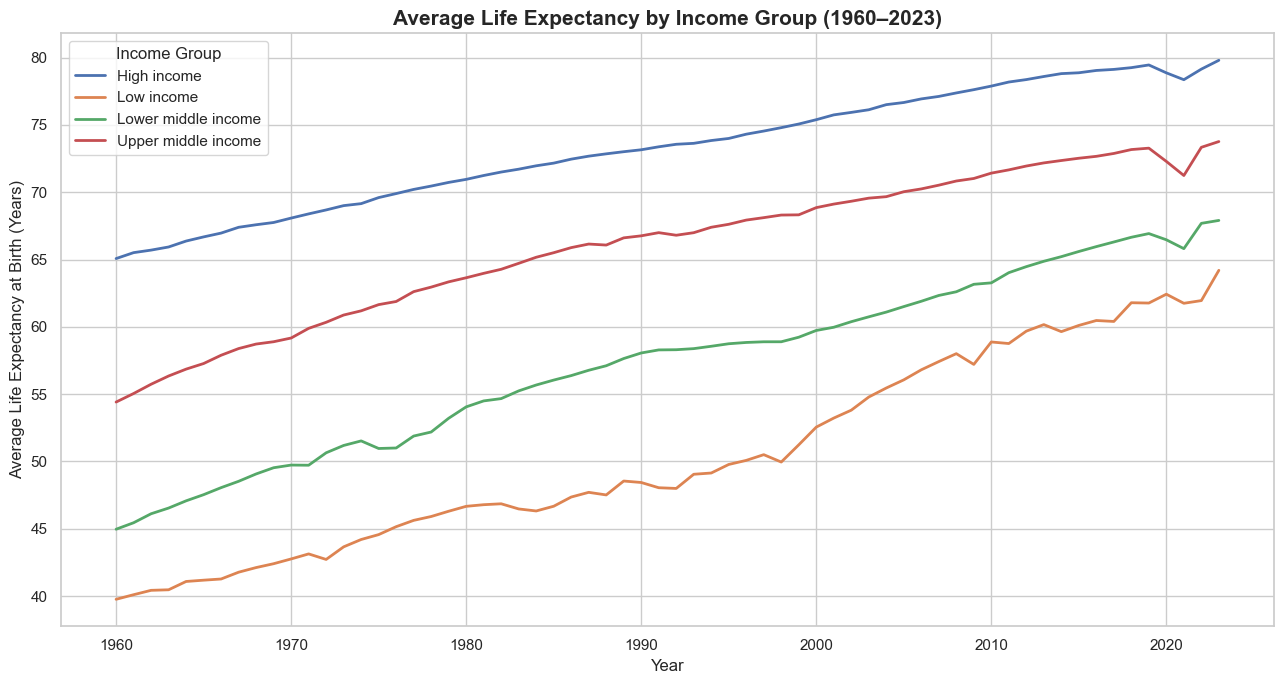

In [17]:
plt.figure(figsize=(13, 7))

sns.lineplot(
    data=income_trend,
    x="year",
    y="mean_life_expectancy",
    hue="income_group",
    linewidth=2
)

plt.title(
    "Average Life Expectancy by Income Group (1960–2023)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Year")
plt.ylabel("Average Life Expectancy at Birth (Years)")
plt.legend(title="Income Group")
plt.tight_layout()
plt.show()

Observation 1 — High-income countries consistently have the highest life expectancy.

They started at approximately 65 years in 1960 and reached close to 80 years by 2023.

Observation 2 — Low-income countries started at the lowest level but experienced substantial improvement.

Their average increased from approximately 40 years to 64 years.

Observation 3 — The gap between income groups persists.

Even though all four groups improved, low-income countries still have considerably lower life expectancy than high-income countries.

Observation 4 — COVID-period decline is visible.

All four groups show a decline around 2020–2021, followed by recovery.

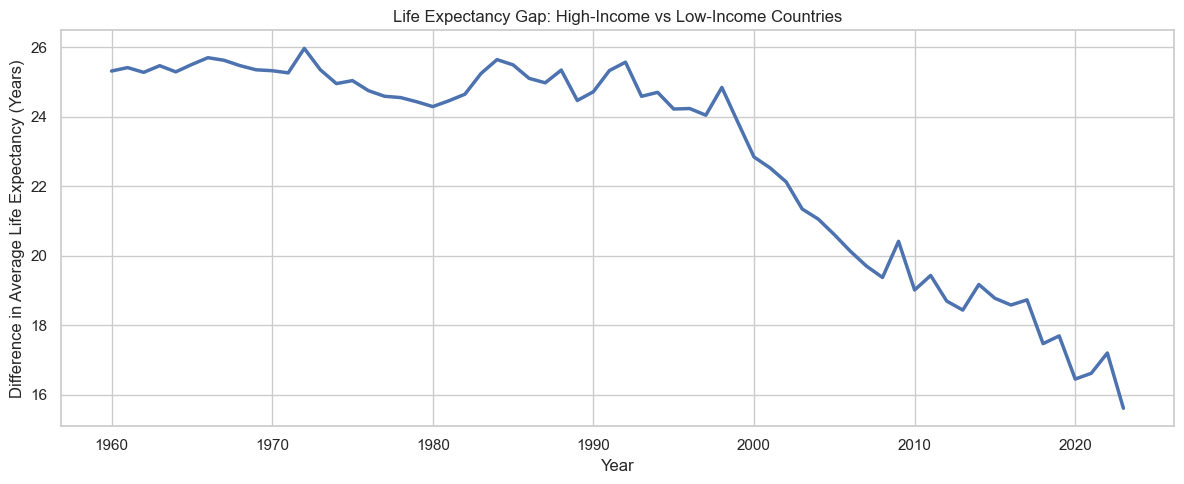

In [18]:
# Calculate the gap between high-income and low-income countries

income_gap = (
    income_trend[
        income_trend["income_group"].isin(
            ["High income", "Low income"]
        )
    ]
    .pivot(
        index="year",
        columns="income_group",
        values="mean_life_expectancy"
    )
    .reset_index()
)

income_gap["high_low_gap"] = (
    income_gap["High income"] - income_gap["Low income"]
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=income_gap,
    x="year",
    y="high_low_gap",
    linewidth=2.5
)

plt.title("Life Expectancy Gap: High-Income vs Low-Income Countries")
plt.xlabel("Year")
plt.ylabel("Difference in Average Life Expectancy (Years)")
plt.tight_layout()
plt.show()

In [19]:
# Extract the first and last year

gap_1960 = income_gap.loc[
    income_gap["year"] == 1960, "high_low_gap"
].iloc[0]

gap_2023 = income_gap.loc[
    income_gap["year"] == 2023, "high_low_gap"
].iloc[0]

gap_reduction = gap_1960 - gap_2023

percentage_reduction = (
    gap_reduction / gap_1960
) * 100

print(f"Gap in 1960: {gap_1960:.2f} years")
print(f"Gap in 2023: {gap_2023:.2f} years")
print(f"Absolute reduction: {gap_reduction:.2f} years")
print(f"Percentage reduction: {percentage_reduction:.2f}%")

Gap in 1960: 25.31 years
Gap in 2023: 15.60 years
Absolute reduction: 9.71 years
Percentage reduction: 38.36%


## For which income group has the difference in average life expectancy between men and women changed the most between 1960 and 2023?

In [20]:
# Calculate country-level gender life expectancy gap

gender_gap_df = country_df.dropna(
    subset=[
        "life_expectancy_female",
        "life_expectancy_male",
        "income_group"
    ]
).copy()

gender_gap_df["gender_gap"] = (
    gender_gap_df["life_expectancy_female"]
    - gender_gap_df["life_expectancy_male"]
)

display(
    gender_gap_df[
        ["country", "year", "income_group", "gender_gap"]
    ].head(10)
)

print("Minimum gender gap:", gender_gap_df["gender_gap"].min())
print("Maximum gender gap:", gender_gap_df["gender_gap"].max())
print("Missing gender gaps:", gender_gap_df["gender_gap"].isna().sum())

,country,year,income_group,gender_gap
0,Aruba,1960,High income,6.71
1,Aruba,1961,High income,6.28
2,Aruba,1962,High income,6.55
3,Aruba,1963,High income,6.79
4,Aruba,1964,High income,7.08
5,Aruba,1965,High income,7.27
6,Aruba,1966,High income,7.21
7,Aruba,1967,High income,7.38
8,Aruba,1968,High income,7.46
9,Aruba,1969,High income,7.50


Minimum gender gap: -4.027999999999999
Maximum gender gap: 26.619999999999997
Missing gender gaps: 0


In [21]:
# Extract observations for 1960 and 2023

endpoint_gender_gap = gender_gap_df[
    gender_gap_df["year"].isin([1960, 2023])
].copy()

# Keep countries with observations in BOTH years
paired_countries = (
    endpoint_gender_gap
    .groupby("country_code")["year"]
    .nunique()
)

paired_country_codes = paired_countries[
    paired_countries == 2
].index

paired_gender_gap = endpoint_gender_gap[
    endpoint_gender_gap["country_code"].isin(
        paired_country_codes
    )
].copy()

print("Countries available in both years:",
      len(paired_country_codes))

gender_gap_comparison = (
    paired_gender_gap
    .groupby(["income_group", "year"])
    .agg(
        average_gender_gap=("gender_gap", "mean"),
        median_gender_gap=("gender_gap", "median"),
        country_count=("country_code", "nunique")
    )
    .reset_index()
)

display(gender_gap_comparison.round(2))

Countries available in both years: 215


,income_group,year,average_gender_gap,median_gender_gap,country_count
0,High income,1960,5.24,5.18,85
1,High income,2023,5.19,5.01,85
2,Low income,1960,2.84,2.72,25
3,Low income,2023,4.40,4.25,25
4,Lower middle income,1960,3.20,3.07,46
5,Lower middle income,2023,4.59,4.48,46
6,Upper middle income,1960,4.26,3.90,59
7,Upper middle income,2023,5.93,5.57,59


In [22]:
gender_gap_pivot = (
    gender_gap_comparison
    .pivot(
        index="income_group",
        columns="year",
        values="average_gender_gap"
    )
)

gender_gap_pivot["absolute_change"] = (
    gender_gap_pivot[2023] - gender_gap_pivot[1960]
)

gender_gap_pivot["absolute_change_magnitude"] = (
    gender_gap_pivot["absolute_change"].abs()
)

display(
    gender_gap_pivot.sort_values(
        "absolute_change_magnitude",
        ascending=False
    ).round(2)
)

year,1960,2023,absolute_change,absolute_change_magnitude
income_group,,,,
Upper middle income,4.26,5.93,1.67,1.67
Low income,2.84,4.40,1.56,1.56
Lower middle income,3.20,4.59,1.39,1.39
High income,5.24,5.19,-0.05,0.05


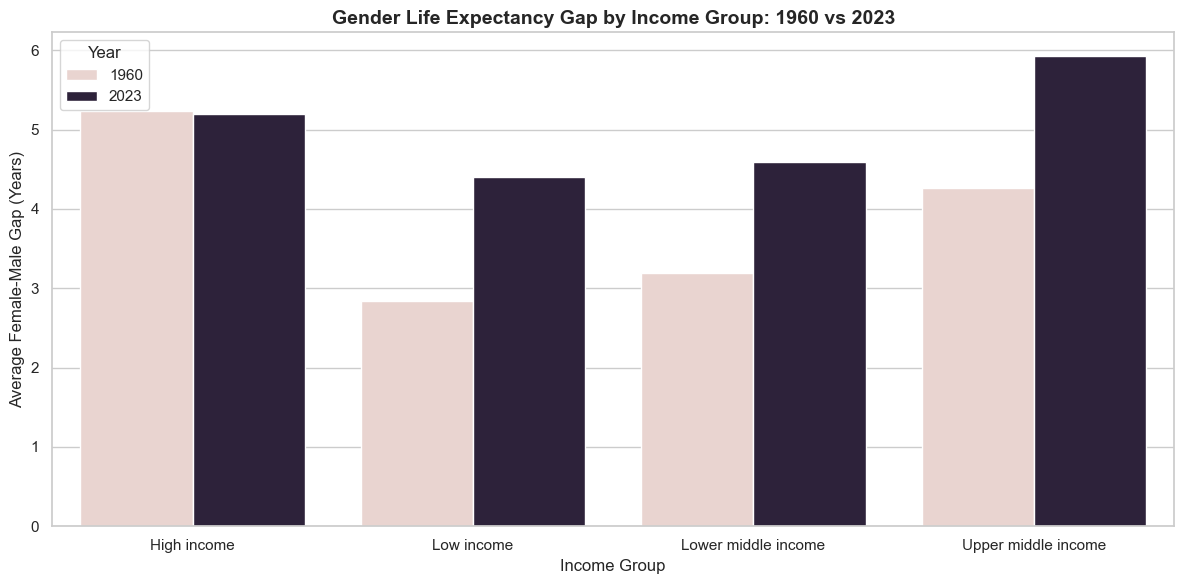

In [23]:
# Prepare data for plotting

gender_gap_plot = gender_gap_comparison.copy()

plt.figure(figsize=(12, 6))

sns.barplot(
    data=gender_gap_plot,
    x="income_group",
    y="average_gender_gap",
    hue="year"
)

plt.title(
    "Gender Life Expectancy Gap by Income Group: 1960 vs 2023",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Income Group")
plt.ylabel("Average Female-Male Gap (Years)")
plt.legend(title="Year")
plt.tight_layout()
plt.show()

### Finding 1: Change in Gender Life Expectancy Gap (1960–2023)

The upper-middle-income group experienced the largest increase in the average gender life expectancy gap between 1960 and 2023, rising from 4.26 years to 5.93 years, an increase of 1.67 years.

The analysis calculates the female-minus-male life expectancy difference at the country-year level and compares income-group averages using a paired sample of 215 countries with valid observations in both endpoint years.

The gender gap increased in three income groups, while the high-income group experienced a marginal decrease of 0.05 years.

**Methodological note:** Income groups are based on the classifications available in the supplied metadata. These classifications are applied retrospectively to historical observations.

In [24]:
# Independent endpoint comparison: all available countries

independent_comparison = (
    gender_gap_df[
        gender_gap_df["year"].isin([1960, 2023])
    ]
    .groupby(["income_group", "year"])
    .agg(
        average_gap=("gender_gap", "mean"),
        country_count=("country_code", "nunique")
    )
    .reset_index()
)

independent_pivot = independent_comparison.pivot(
    index="income_group",
    columns="year",
    values="average_gap"
)

independent_pivot["change"] = (
    independent_pivot[2023] - independent_pivot[1960]
)

independent_pivot["absolute_change"] = (
    independent_pivot["change"].abs()
)

display(independent_pivot.round(2))

comparison_results = pd.DataFrame({
    "independent_change": independent_pivot["change"],
    "paired_change": gender_gap_pivot["absolute_change"] * 0
        + gender_gap_pivot["absolute_change"]
})

# Replace paired_change with the signed endpoint difference
comparison_results["paired_change"] = (
    gender_gap_pivot[2023] - gender_gap_pivot[1960]
)

display(comparison_results.round(2))

year,1960,2023,change,absolute_change
income_group,,,,
High income,5.24,5.18,-0.05,0.05
Low income,2.84,4.40,1.56,1.56
Lower middle income,3.20,4.74,1.54,1.54
Upper middle income,4.26,5.93,1.67,1.67


,independent_change,paired_change
income_group,,
High income,-0.05,-0.05
Low income,1.56,1.56
Lower middle income,1.54,1.39
Upper middle income,1.67,1.67


### Statistical Analysis 1: Change in Gender Life Expectancy Gap

The upper-middle-income group experienced the largest increase in the average female-minus-male life expectancy gap between 1960 and 2023, increasing by approximately 1.67 years (from 4.26 to 5.93 years).

The finding was consistent across two approaches:

- **Independent endpoint comparison:** Uses all countries with available observations in each year.
- **Paired endpoint comparison:** Uses only countries with valid observations in both 1960 and 2023.

Both approaches identified upper-middle-income countries as having the largest increase. The paired comparison included 215 countries across the four income groups.

The consistency of the result provides confidence that the main finding is not driven by changes in country coverage.

**Limitation:** Income-group classifications from the supplied metadata are applied retrospectively to historical observations.

In [25]:
# Identify countries with gender gap data in all 64 years

country_year_counts = (
    gender_gap_df
    .groupby("country_code")["year"]
    .nunique()
)

balanced_countries = country_year_counts[
    country_year_counts == 64
].index

balanced_gender_gap = gender_gap_df[
    gender_gap_df["country_code"].isin(balanced_countries)
].copy()

print("Countries in balanced panel:", len(balanced_countries))
print("Total observations:", len(balanced_gender_gap))

Countries in balanced panel: 215
Total observations: 13760


In [26]:
# Calculate annual average gender gap by income group

annual_gender_gap = (
    gender_gap_df
    .groupby(["year", "income_group"])
    .agg(
        average_gender_gap=("gender_gap", "mean"),
        median_gender_gap=("gender_gap", "median"),
        country_count=("country_code", "nunique")
    )
    .reset_index()
)

display(annual_gender_gap.head(10))

,year,income_group,average_gender_gap,median_gender_gap,country_count
0,1960,High income,5.24,5.18,85
1,1960,Low income,2.84,2.72,25
2,1960,Lower middle income,3.20,3.07,46
3,1960,Upper middle income,4.26,3.90,59
4,1961,High income,5.28,5.20,86
5,1961,Low income,2.84,2.67,25
6,1961,Lower middle income,3.27,3.04,46
7,1961,Upper middle income,4.28,3.98,59
8,1962,High income,5.34,5.25,86
9,1962,Low income,2.85,2.67,25


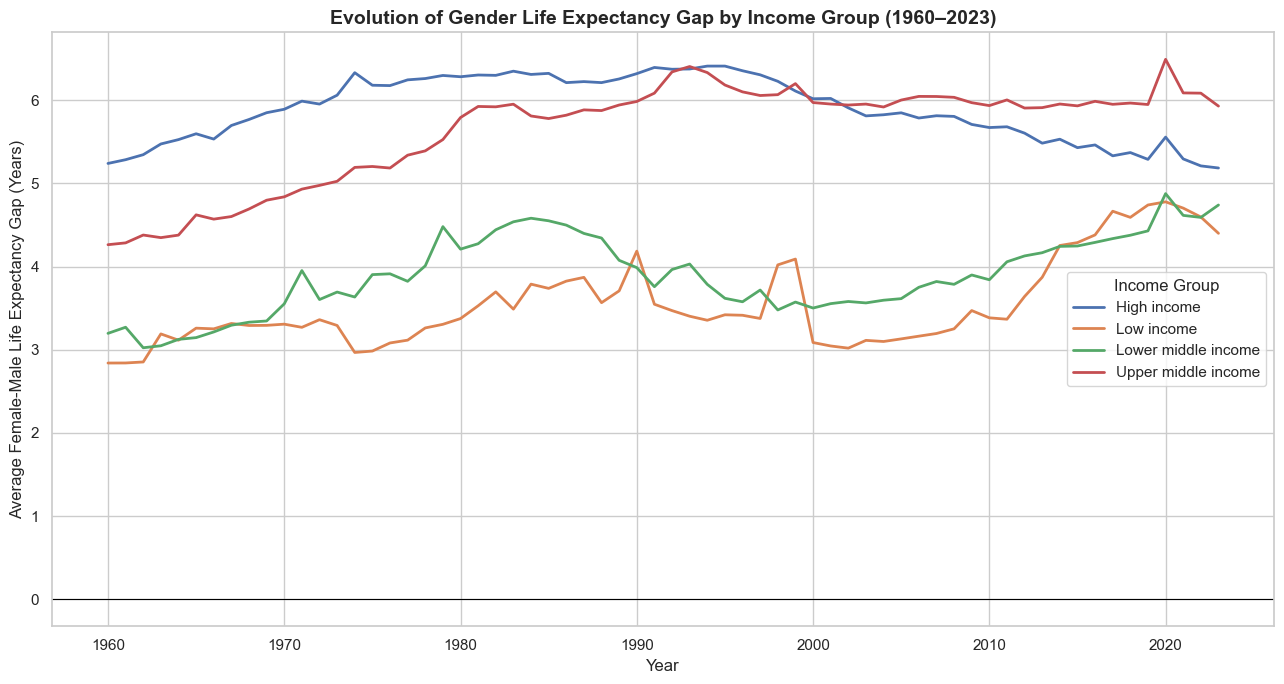

In [27]:
plt.figure(figsize=(13, 7))

sns.lineplot(
    data=annual_gender_gap,
    x="year",
    y="average_gender_gap",
    hue="income_group",
    linewidth=2
)

plt.title(
    "Evolution of Gender Life Expectancy Gap by Income Group (1960–2023)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Year")
plt.ylabel("Average Female-Male Life Expectancy Gap (Years)")
plt.axhline(0, color="black", linewidth=0.8)
plt.legend(title="Income Group")
plt.tight_layout()
plt.show()

Countries in balanced panel: 215
Total observations: 13760


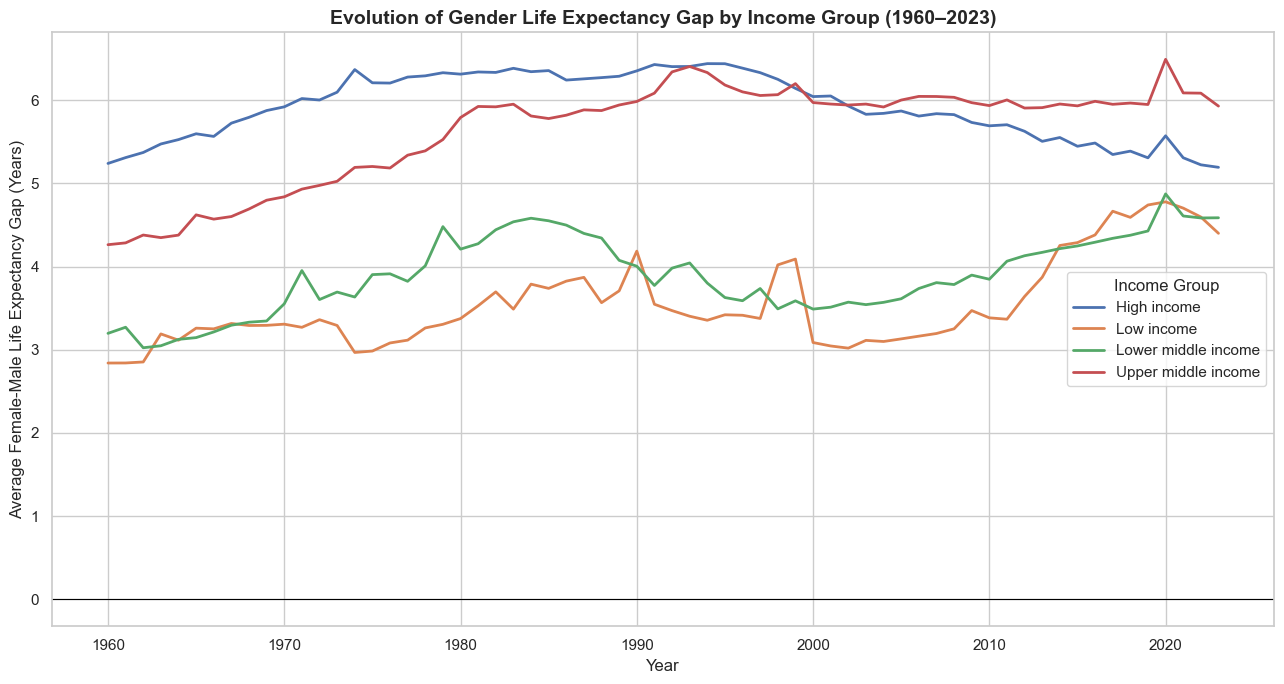

In [28]:
# Identify countries with gender gap data in all 64 years

country_year_counts = (
    gender_gap_df
    .groupby("country_code")["year"]
    .nunique()
)

balanced_countries = country_year_counts[
    country_year_counts == 64
].index

balanced_gender_gap = gender_gap_df[
    gender_gap_df["country_code"].isin(balanced_countries)
].copy()

print("Countries in balanced panel:", len(balanced_countries))
print("Total observations:", len(balanced_gender_gap))

balanced_annual_gap = (
    balanced_gender_gap
    .groupby(["year", "income_group"])
    .agg(
        average_gender_gap=("gender_gap", "mean"),
        country_count=("country_code", "nunique")
    )
    .reset_index()
)

plt.figure(figsize=(13, 7))

sns.lineplot(
    data=balanced_annual_gap,
    x="year",
    y="average_gender_gap",
    hue="income_group",
    linewidth=2
)

plt.title(
    "Evolution of Gender Life Expectancy Gap by Income Group (1960–2023)",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Year")
plt.ylabel("Average Female-Male Life Expectancy Gap (Years)")
plt.axhline(0, color="black", linewidth=0.8)
plt.legend(title="Income Group")
plt.tight_layout()
plt.show()

The upper-middle-income group has an interesting trajectory.

Its gender gap increased from 4.26 years in 1960 to 5.93 years in 2023. But the annual trend suggests that much of this increase happened during the earlier decades, rather than uniformly across the entire period.

## For which income group has variability in life expectancy at birth changed the most between 1960 and 2023?

In [29]:
# All available country observations in 1960 and 2023

independent_le = country_df[
    country_df["year"].isin([1960, 2023])
].dropna(
    subset=["life_expectancy_total", "income_group"]
).copy()

# Calculate variability by income group and year

independent_variability = (
    independent_le
    .groupby(["income_group", "year"])
    .agg(
        mean_le=("life_expectancy_total", "mean"),
        std_le=("life_expectancy_total", "std"),
        median_le=("life_expectancy_total", "median"),
        q1=("life_expectancy_total", lambda x: x.quantile(0.25)),
        q3=("life_expectancy_total", lambda x: x.quantile(0.75)),
        country_count=("country_code", "nunique")
    )
    .reset_index()
)

independent_variability["iqr"] = (
    independent_variability["q3"]
    - independent_variability["q1"]
)

display(independent_variability.round(2))

,income_group,year,mean_le,std_le,median_le,q1,q3,country_count,iqr
0,High income,1960,65.08,6.91,67.53,62.45,69.87,85,7.41
1,High income,2023,79.81,4.18,81.13,77.37,82.94,86,5.57
2,Low income,1960,39.76,6.76,39.22,34.99,43.35,25,8.36
3,Low income,2023,64.20,4.60,63.65,61.18,67.35,25,6.17
4,Lower middle income,1960,44.97,6.34,44.07,41.21,47.89,46,6.68
5,Lower middle income,2023,67.91,4.90,67.65,65.05,71.71,47,6.66
6,Upper middle income,1960,54.41,7.55,55.15,50.60,59.12,59,8.52
7,Upper middle income,2023,73.77,3.78,74.18,71.35,77.27,59,5.92


In [30]:
# Pivot standard deviation for endpoint comparison

independent_std = (
    independent_variability
    .pivot(
        index="income_group",
        columns="year",
        values="std_le"
    )
)

independent_std["sd_change"] = (
    independent_std[2023] - independent_std[1960]
)

independent_std["absolute_sd_change"] = (
    independent_std["sd_change"].abs()
)

display(
    independent_std.sort_values(
        "absolute_sd_change",
        ascending=False
    ).round(2)
)

year,1960,2023,sd_change,absolute_sd_change
income_group,,,,
Upper middle income,7.55,3.78,-3.77,3.77
High income,6.91,4.18,-2.73,2.73
Low income,6.76,4.60,-2.16,2.16
Lower middle income,6.34,4.90,-1.44,1.44


In [31]:
# Reuse the paired country codes from Question 1

paired_country_codes = paired_gender_gap["country_code"].unique()

paired_le = country_df[
    country_df["country_code"].isin(paired_country_codes)
    & country_df["year"].isin([1960, 2023])
].dropna(
    subset=["life_expectancy_total", "income_group"]
).copy()

print("Countries:", paired_le["country_code"].nunique())
print("Observations:", len(paired_le))

Countries: 215
Observations: 430


In [32]:
paired_variability = (
    paired_le
    .groupby(["income_group", "year"])
    .agg(
        std_le=("life_expectancy_total", "std"),
        country_count=("country_code", "nunique")
    )
    .reset_index()
)

paired_std = (
    paired_variability
    .pivot(
        index="income_group",
        columns="year",
        values="std_le"
    )
)

paired_std["sd_change"] = (
    paired_std[2023] - paired_std[1960]
)

paired_std["absolute_sd_change"] = (
    paired_std["sd_change"].abs()
)

display(
    paired_std.sort_values(
        "absolute_sd_change",
        ascending=False
    ).round(2)
)

year,1960,2023,sd_change,absolute_sd_change
income_group,,,,
Upper middle income,7.55,3.78,-3.77,3.77
High income,6.91,4.19,-2.72,2.72
Low income,6.76,4.60,-2.16,2.16
Lower middle income,6.34,4.93,-1.40,1.40


In [33]:
independent_iqr = independent_variability.pivot(
    index="income_group",
    columns="year",
    values="iqr"
)

independent_iqr["iqr_change"] = (
    independent_iqr[2023] - independent_iqr[1960]
)

independent_iqr["absolute_iqr_change"] = (
    independent_iqr["iqr_change"].abs()
)

independent_iqr.sort_values(
    "absolute_iqr_change",
    ascending=False
)

year,1960,2023,iqr_change,absolute_iqr_change
income_group,,,,
Upper middle income,8.52,5.92,-2.60,2.60
Low income,8.36,6.17,-2.19,2.19
High income,7.41,5.57,-1.84,1.84
Lower middle income,6.68,6.66,-0.02,0.02


Upper-middle-income countries experienced the largest reduction in cross-country variability in life expectancy between 1960 and 2023. Their standard deviation decreased from 7.55 to 3.78 years, a reduction of 3.77 years. The interquartile range also declined from 8.52 to 5.92 years, a reduction of 2.60 years. Since both measures identify the same income group, the finding is robust to the choice of dispersion statistic. This suggests increasing convergence in life expectancy across countries within the upper-middle-income group.

In [34]:
annual_variability = (
    country_df
    .dropna(subset=["life_expectancy_total", "income_group"])
    .groupby(["year", "income_group"])
    .agg(
        mean_le=("life_expectancy_total", "mean"),
        std_le=("life_expectancy_total", "std"),
        median_le=("life_expectancy_total", "median"),
        q1=("life_expectancy_total", lambda x: x.quantile(0.25)),
        q3=("life_expectancy_total", lambda x: x.quantile(0.75)),
        country_count=("country_code", "nunique")
    )
    .reset_index()
)

annual_variability["iqr"] = (
    annual_variability["q3"] - annual_variability["q1"]
)

annual_variability.head()

,year,income_group,mean_le,std_le,median_le,q1,q3,country_count,iqr
0,1960,High income,65.08,6.91,67.53,62.45,69.87,85,7.41
1,1960,Low income,39.76,6.76,39.22,34.99,43.35,25,8.36
2,1960,Lower middle income,44.97,6.34,44.07,41.21,47.89,46,6.68
3,1960,Upper middle income,54.41,7.55,55.15,50.60,59.12,59,8.52
4,1961,High income,65.52,6.73,67.78,62.70,70.25,86,7.55


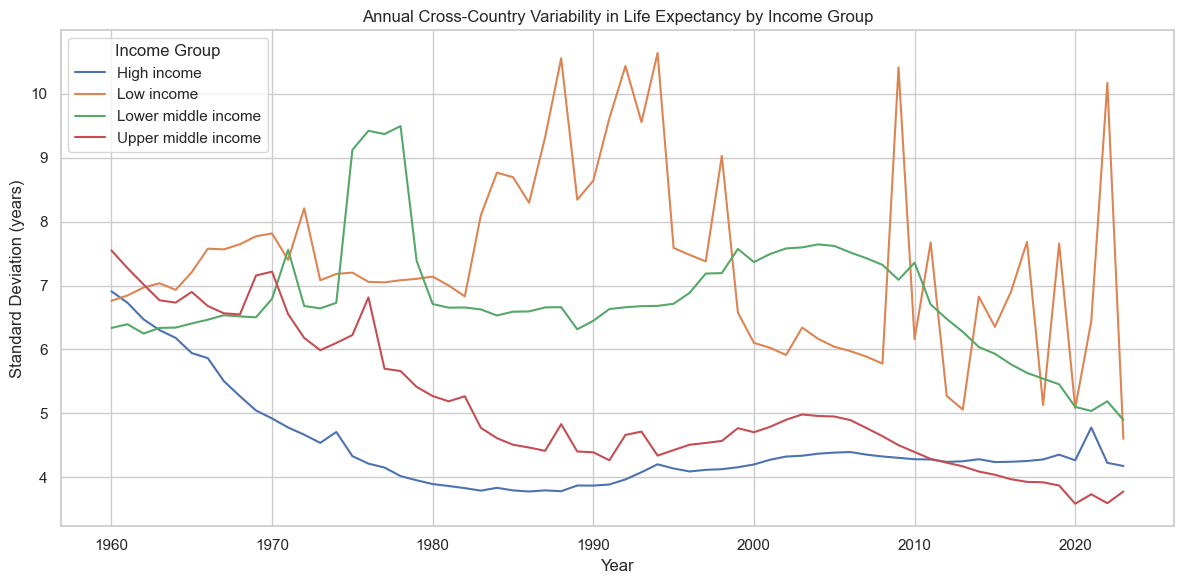

In [35]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=annual_variability,
    x="year",
    y="std_le",
    hue="income_group"
)

plt.title("Annual Cross-Country Variability in Life Expectancy by Income Group")
plt.xlabel("Year")
plt.ylabel("Standard Deviation (years)")
plt.legend(title="Income Group")
plt.tight_layout()
plt.show()

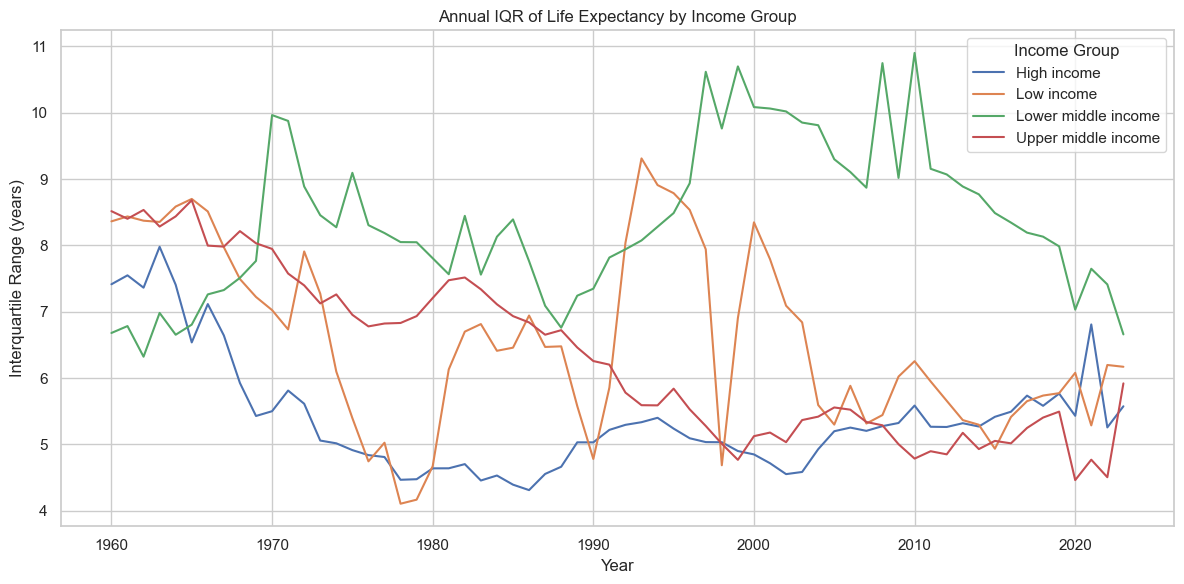

In [36]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=annual_variability,
    x="year",
    y="iqr",
    hue="income_group"
)

plt.title("Annual IQR of Life Expectancy by Income Group")
plt.xlabel("Year")
plt.ylabel("Interquartile Range (years)")
plt.legend(title="Income Group")
plt.tight_layout()
plt.show()

## Identify the countries with the highest and lowest correlation between fertility rate and life expectancy over time.

In [37]:
correlation_df = country_df.dropna(
    subset=["fertility_rate", "life_expectancy_total"]
).copy()

country_correlations = (
    correlation_df
    .groupby(["country", "country_code"])
    .apply(
        lambda group: group["fertility_rate"].corr(
            group["life_expectancy_total"]
        ),
        include_groups=False
    )
    .reset_index(name="correlation")
)

country_correlations = country_correlations.dropna(
    subset=["correlation"]
)

country_correlations["absolute_correlation"] = (
    country_correlations["correlation"].abs()
)

print("Countries analysed:", len(country_correlations))

country_correlations.sort_values(
    "correlation",
    ascending=True
).head(10)

Countries analysed: 217


,country,country_code,correlation,absolute_correlation
89,India,IND,-1.00,1.00
28,Brunei Darussalam,BRN,-0.99,0.99
74,Ghana,GHA,-0.99,0.99
198,Turkiye,TUR,-0.99,0.99
200,Turks and Caicos Islands,TCA,-0.99,0.99
56,Dominican Republic,DOM,-0.99,0.99
120,Malaysia,MYS,-0.99,0.99
58,"Egypt, Arab Rep.",EGY,-0.99,0.99
1,Albania,ALB,-0.99,0.99
57,Ecuador,ECU,-0.99,0.99


In [38]:
country_correlations = (
    correlation_df
    .groupby(["country", "country_code"])
    .agg(
        correlation=(
            "fertility_rate",
            lambda x: x.corr(
                correlation_df.loc[x.index, "life_expectancy_total"]
            )
        ),
        observation_count=("year", "nunique"),
        first_year=("year", "min"),
        last_year=("year", "max")
    )
    .reset_index()
)

display(country_correlations)

,country,country_code,correlation,observation_count,first_year,last_year
0,Afghanistan,AFG,-0.73,64,1960,2023
1,Albania,ALB,-0.99,64,1960,2023
2,Algeria,DZA,-0.95,64,1960,2023
3,American Samoa,ASM,-0.90,64,1960,2023
4,Andorra,AND,-0.90,64,1960,2023
...,...,...,...,...,...,...
212,Virgin Islands (U.S.),VIR,-0.90,64,1960,2023
213,West Bank and Gaza,PSE,-0.73,34,1990,2023
214,"Yemen, Rep.",YEM,-0.74,64,1960,2023
215,Zambia,ZMB,-0.53,64,1960,2023


In [39]:
# Strongest negative correlations
print("10 strongest negative correlations")

display(
    country_correlations
    .sort_values("correlation")
    .head(10)
)

# Strongest positive correlations
print("10 strongest positive correlations")

display(
    country_correlations
    .sort_values("correlation", ascending=False)
    .head(10)
)

10 strongest negative correlations


,country,country_code,correlation,observation_count,first_year,last_year
89,India,IND,-1.00,64,1960,2023
28,Brunei Darussalam,BRN,-0.99,64,1960,2023
74,Ghana,GHA,-0.99,64,1960,2023
198,Turkiye,TUR,-0.99,64,1960,2023
200,Turks and Caicos Islands,TCA,-0.99,64,1960,2023
56,Dominican Republic,DOM,-0.99,64,1960,2023
120,Malaysia,MYS,-0.99,64,1960,2023
58,"Egypt, Arab Rep.",EGY,-0.99,64,1960,2023
1,Albania,ALB,-0.99,64,1960,2023
57,Ecuador,ECU,-0.99,64,1960,2023


10 strongest positive correlations


,country,country_code,correlation,observation_count,first_year,last_year
216,Zimbabwe,ZWE,0.35,64,1960,2023
111,Lesotho,LSO,0.32,64,1960,2023
161,Russian Federation,RUS,0.20,64,1960,2023
38,Chad,TCD,0.16,64,1960,2023
203,Ukraine,UKR,0.14,64,1960,2023
44,"Congo, Dem. Rep.",COD,0.12,64,1960,2023
37,Central African Republic,CAF,0.09,64,1960,2023
63,Eswatini,SWZ,0.04,64,1960,2023
17,Belarus,BLR,0.02,64,1960,2023
25,Botswana,BWA,-0.19,64,1960,2023


In [40]:
# Compare year-to-year changes rather than long-run levels.
# This helps distinguish short-term co-movement from correlations driven
# mainly by long-term trends.

correlation_df = correlation_df.sort_values(
    ["country_code", "year"]
).copy()

correlation_df["fertility_change"] = (
    correlation_df.groupby("country_code")["fertility_rate"].diff()
)

correlation_df["life_expectancy_change"] = (
    correlation_df.groupby("country_code")["life_expectancy_total"].diff()
)

change_correlation = (
    correlation_df
    .dropna(subset=["fertility_change", "life_expectancy_change"])
    .groupby(["country", "country_code"])
    .agg(
        change_correlation=(
            "fertility_change",
            lambda x: x.corr(
                correlation_df.loc[x.index, "life_expectancy_change"]
            )
        ),
        observation_count=("year", "nunique"),
        first_year=("year", "min"),
        last_year=("year", "max")
    )
    .reset_index()
)

change_correlation = change_correlation.dropna(
    subset=["change_correlation"]
)

display(change_correlation.sort_values("change_correlation").head(10))
display(change_correlation.sort_values("change_correlation", ascending=False).head(10))

,country,country_code,change_correlation,observation_count,first_year,last_year
150,Palau,PLW,-0.47,63,1961,2023
192,Thailand,THA,-0.40,63,1961,2023
210,"Venezuela, RB",VEN,-0.38,63,1961,2023
28,Brunei Darussalam,BRN,-0.35,63,1961,2023
202,Uganda,UGA,-0.34,63,1961,2023
160,Romania,ROU,-0.30,63,1961,2023
200,Turks and Caicos Islands,TCA,-0.30,63,1961,2023
170,Sierra Leone,SLE,-0.30,63,1961,2023
6,Antigua and Barbuda,ATG,-0.29,63,1961,2023
1,Albania,ALB,-0.28,63,1961,2023


,country,country_code,change_correlation,observation_count,first_year,last_year
70,Gabon,GAB,0.80,63,1961,2023
33,Cambodia,KHM,0.62,63,1961,2023
47,Cote d'Ivoire,CIV,0.58,63,1961,2023
101,Kenya,KEN,0.53,63,1961,2023
166,Saudi Arabia,SAU,0.48,63,1961,2023
41,China,CHN,0.47,63,1961,2023
124,Marshall Islands,MHL,0.45,63,1961,2023
128,"Micronesia, Fed. Sts.",FSM,0.45,63,1961,2023
25,Botswana,BWA,0.43,63,1961,2023
136,Namibia,NAM,0.40,63,1961,2023


In [41]:
reliable_correlations = change_correlation[
    change_correlation["observation_count"] >= 30
].copy()

print("Countries meeting threshold:", len(reliable_correlations))

display(
    reliable_correlations.nsmallest(10, "change_correlation")
)

display(
    reliable_correlations.nlargest(10, "change_correlation")
)

Countries meeting threshold: 217


,country,country_code,change_correlation,observation_count,first_year,last_year
150,Palau,PLW,-0.47,63,1961,2023
192,Thailand,THA,-0.40,63,1961,2023
210,"Venezuela, RB",VEN,-0.38,63,1961,2023
28,Brunei Darussalam,BRN,-0.35,63,1961,2023
202,Uganda,UGA,-0.34,63,1961,2023
160,Romania,ROU,-0.30,63,1961,2023
200,Turks and Caicos Islands,TCA,-0.30,63,1961,2023
170,Sierra Leone,SLE,-0.30,63,1961,2023
6,Antigua and Barbuda,ATG,-0.29,63,1961,2023
1,Albania,ALB,-0.28,63,1961,2023


,country,country_code,change_correlation,observation_count,first_year,last_year
70,Gabon,GAB,0.80,63,1961,2023
33,Cambodia,KHM,0.62,63,1961,2023
47,Cote d'Ivoire,CIV,0.58,63,1961,2023
101,Kenya,KEN,0.53,63,1961,2023
166,Saudi Arabia,SAU,0.48,63,1961,2023
41,China,CHN,0.47,63,1961,2023
124,Marshall Islands,MHL,0.45,63,1961,2023
128,"Micronesia, Fed. Sts.",FSM,0.45,63,1961,2023
25,Botswana,BWA,0.43,63,1961,2023
136,Namibia,NAM,0.40,63,1961,2023


In [42]:
map_df = country_df[
    (country_df["year"] == 2023)
    & country_df["life_expectancy_total"].notna()
].copy()

print("Countries available:", map_df["country_code"].nunique())
print("Missing life expectancy:", map_df["life_expectancy_total"].isna().sum())

display(
    map_df[
        ["country", "country_code", "region",
         "income_group", "life_expectancy_total"]
    ].head(10)
)

Countries available: 217
Missing life expectancy: 0


,country,country_code,region,income_group,life_expectancy_total
63,Aruba,ABW,Latin America & Caribbean,High income,76.35
191,Afghanistan,AFG,Middle East & North Africa,Low income,66.03
319,Angola,AGO,Sub-Saharan Africa,Lower middle income,64.62
383,Albania,ALB,Europe & Central Asia,Upper middle income,79.60
447,Andorra,AND,Europe & Central Asia,High income,84.04
575,United Arab Emirates,ARE,Middle East & North Africa,High income,82.91
639,Argentina,ARG,Latin America & Caribbean,Upper middle income,77.39
703,Armenia,ARM,Europe & Central Asia,Upper middle income,77.47
767,American Samoa,ASM,East Asia & Pacific,High income,72.85
831,Antigua and Barbuda,ATG,Latin America & Caribbean,High income,77.60


# Data Visualization

## Create a world map where each country is color coded according to how
high or low the life expectancy at birth is in 2023.

**Dependency note:** Plotly is included in the project environment through `requirements.txt`.
If it is not installed, activate the project virtual environment and run `pip install plotly`
in the terminal before executing this notebook.

In [43]:
import plotly.express as px

In [44]:
fig = px.choropleth(
    map_df, range_color=(50, 90),
    locations="country_code",
    locationmode="ISO-3",
    color="life_expectancy_total",
    hover_name="country",
    hover_data={
        "country_code": True,
        "income_group": True,
        "life_expectancy_total": ":.1f"
    },
    color_continuous_scale="Viridis",
    title="Life Expectancy at Birth Across Countries (2023)",
    labels={
        "life_expectancy_total": "Life expectancy (years)"
    }
)

fig.add_annotation(
    text="Source: World Bank | Indicator: SP.DYN.LE00.IN",
    xref="paper",
    yref="paper",
    x=0,
    y=-0.08,
    showarrow=False,
    font=dict(size=10, color="gray")
)

fig.update_layout(
    geo=dict(
        showframe=False,
        showcoastlines=True,
        projection_type="natural earth"
    ),
    title_x=0.5
)

fig.show()

In [45]:
# Select observations from 1960 and 2023

# To make the transition comparison fair, include only countries with
# non-missing life expectancy observations in both endpoint years.
ranking_df = country_df[
    country_df["year"].isin([1960, 2023])
].dropna(
    subset=["life_expectancy_total"]
).copy()

# Keep only countries with observations in both years
country_counts = ranking_df.groupby("country_code")["year"].nunique()

common_countries = country_counts[
    country_counts == 2
].index

ranking_df = ranking_df[
    ranking_df["country_code"].isin(common_countries)
].copy()

print("Countries included:", len(common_countries))
print("Total observations:", len(ranking_df))

display(
    ranking_df[
        ["country", "country_code", "year", "life_expectancy_total"]
    ].head(10)
)

Countries included: 215
Total observations: 430


,country,country_code,year,life_expectancy_total
0,Aruba,ABW,1960,64.05
63,Aruba,ABW,2023,76.35
128,Afghanistan,AFG,1960,32.80
191,Afghanistan,AFG,2023,66.03
256,Angola,AGO,1960,37.93
319,Angola,AGO,2023,64.62
320,Albania,ALB,1960,56.41
383,Albania,ALB,2023,79.60
384,Andorra,AND,1960,72.09
447,Andorra,AND,2023,84.04


In [46]:
# Define five life expectancy categories
bucket_labels = [
    "Very low life expectancy",
    "Low life expectancy",
    "Medium life expectancy",
    "High life expectancy",
    "Very high life expectancy"
]

# Rank countries separately within each year
ranking_df["rank"] = (
    ranking_df.groupby("year")["life_expectancy_total"]
    .rank(method="first")
)

# Assign five approximately equal-sized groups
ranking_df["bucket"] = (
    ranking_df.groupby("year")["rank"]
    .transform(
        lambda x: pd.qcut(
            x,
            q=5,
            labels=bucket_labels
        )
    )
)

display(
    ranking_df[
        ["country", "year", "life_expectancy_total", "rank", "bucket"]
    ].head(15)
)

,country,year,life_expectancy_total,rank,bucket
0,Aruba,1960,64.05,157.00,High life expectancy
63,Aruba,2023,76.35,125.00,Medium life expectancy
128,Afghanistan,1960,32.80,4.00,Very low life expectancy
191,Afghanistan,2023,66.03,33.00,Very low life expectancy
256,Angola,1960,37.93,20.00,Very low life expectancy
319,Angola,2023,64.62,27.00,Very low life expectancy
320,Albania,1960,56.41,107.00,Medium life expectancy
383,Albania,2023,79.60,163.00,High life expectancy
384,Andorra,1960,72.09,207.00,Very high life expectancy
447,Andorra,2023,84.04,208.00,Very high life expectancy


In [47]:
bucket_distribution = (
    ranking_df
    .groupby(["year", "bucket"], observed=False)
    .agg(country_count=("country_code", "nunique"))
    .reset_index()
)

display(
    bucket_distribution.pivot(
        index="bucket",
        columns="year",
        values="country_count"
    )
)

year,1960,2023
bucket,,
Very low life expectancy,43,43
Low life expectancy,43,43
Medium life expectancy,43,43
High life expectancy,43,43
Very high life expectancy,43,43


In [48]:
# Create one row per country
country_transitions = (
    ranking_df
    .pivot(
        index=["country_code", "country"],
        columns="year",
        values="bucket"
    )
    .reset_index()
)

country_transitions = country_transitions.rename(
    columns={
        1960: "bucket_1960",
        2023: "bucket_2023"
    }
)

display(country_transitions.head(10))

transition_matrix = pd.crosstab(
    country_transitions["bucket_1960"],
    country_transitions["bucket_2023"]
)

transition_matrix = transition_matrix.reindex(
    index=bucket_labels,
    columns=bucket_labels,
    fill_value=0
)

display(transition_matrix)

year,country_code,country,bucket_1960,bucket_2023
0,ABW,Aruba,High life expectancy,Medium life expectancy
1,AFG,Afghanistan,Very low life expectancy,Very low life expectancy
2,AGO,Angola,Very low life expectancy,Very low life expectancy
3,ALB,Albania,Medium life expectancy,High life expectancy
4,AND,Andorra,Very high life expectancy,Very high life expectancy
5,ARE,United Arab Emirates,Low life expectancy,Very high life expectancy
6,ARG,Argentina,High life expectancy,High life expectancy
7,ARM,Armenia,High life expectancy,High life expectancy
8,ASM,American Samoa,High life expectancy,Medium life expectancy
9,ATG,Antigua and Barbuda,High life expectancy,High life expectancy


bucket_2023,Very low life expectancy,Low life expectancy,Medium life expectancy,High life expectancy,Very high life expectancy
bucket_1960,,,,,
Very low life expectancy,25,11,3,4,0
Low life expectancy,14,15,8,4,2
Medium life expectancy,4,13,14,9,3
High life expectancy,0,4,14,17,8
Very high life expectancy,0,0,4,9,30


In [49]:
# Countries that remained in the same bucket
stayed_same = sum(
    transition_matrix.loc[bucket, bucket]
    for bucket in bucket_labels
)

total_countries = transition_matrix.values.sum()

# Countries that changed buckets
moved = total_countries - stayed_same

print("Total countries:", total_countries)
print("Stayed in same bucket:", stayed_same)
print("Moved to another bucket:", moved)
print("Percentage unchanged:", round(stayed_same / total_countries * 100, 2))
print("Percentage moved:", round(moved / total_countries * 100, 2))

Total countries: 215
Stayed in same bucket: 101
Moved to another bucket: 114
Percentage unchanged: 46.98
Percentage moved: 53.02


In [50]:
import plotly.graph_objects as go

# Create nodes for both years
labels = (
    [f"1960 - {b}" for b in bucket_labels]
    + [f"2023 - {b}" for b in bucket_labels]
)

source = []
target = []
values = []

for i, old_bucket in enumerate(bucket_labels):
    for j, new_bucket in enumerate(bucket_labels):

        count = transition_matrix.loc[old_bucket, new_bucket]

        if count > 0:
            source.append(i)
            target.append(len(bucket_labels) + j)
            values.append(count)

fig = go.Figure(
    data=[
        go.Sankey(
            node=dict(
                pad=20,
                thickness=20,
                label=labels
            ),
            link=dict(
                source=source,
                target=target,
                value=values
            )
        )
    ]
)

fig.update_layout(
    title="Country Life Expectancy Ranking Transitions: 1960 vs 2023",
    title_x=0.5,
    font_size=11,
    height=650
)

fig.show()